In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [78]:
sdf = pd.read_csv('bm_sales.csv')
pdf = pd.read_csv('bm_skus.csv')
stdf = pd.read_csv('bm_stores.csv')



Data Inspection

In [79]:
sdf.head()

,date,store_id,sku_id,customer_id,quantity,unit_price,total_value,channel,discount_pct
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0


In [80]:
sdf.columns

Index(['date', 'store_id', 'sku_id', 'customer_id', 'quantity', 'unit_price',
       'total_value', 'channel', 'discount_pct'],
      dtype='str')

In [81]:
sdf.shape

(641843, 9)

In [82]:
sdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 641843 entries, 0 to 641842
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   date          641843 non-null  str    
 1   store_id      641843 non-null  int64  
 2   sku_id        641843 non-null  int64  
 3   customer_id   482022 non-null  float64
 4   quantity      641843 non-null  int64  
 5   unit_price    641843 non-null  float64
 6   total_value   641843 non-null  float64
 7   channel       641843 non-null  str    
 8   discount_pct  641843 non-null  float64
dtypes: float64(4), int64(3), str(2)
memory usage: 54.2 MB


In [83]:
sdf.describe()

,store_id,sku_id,customer_id,quantity,unit_price,total_value,discount_pct
count,641843.000000,641843.000000,482022.000000,641843.000000,641843.000000,641843.000000,641843.000000
mean,25.491081,1100.547835,2504.986828,2.613120,44.109242,114.069845,5.411316
std,14.437269,57.684158,1442.340254,1.481563,48.984342,157.206354,8.664765
min,1.000000,1001.000000,1.000000,1.000000,1.700000,1.700000,0.000000
25%,13.000000,1051.000000,1260.000000,1.000000,14.280000,27.320000,0.000000
50%,25.000000,1101.000000,2507.000000,2.000000,24.330000,57.660000,0.000000
75%,38.000000,1150.000000,3752.000000,4.000000,49.570000,129.550000,10.000000
max,50.000000,1200.000000,5000.000000,6.000000,245.380000,1472.280000,35.000000


In [84]:
pdf.head()

,sku_id,sku_name,category,subcategory,unit_price,cost_price,brand
0,1001,Electronics_Chargers_1001,Electronics,Chargers,164.56,103.44,Budget
1,1002,Dairy_Cream_1002,Dairy,Cream,13.73,8.96,Local
2,1003,Household_Cleaning Supplies_1003,Household,Cleaning Supplies,12.00,7.47,BlueMart
3,1004,Beverages_Juices_1004,Beverages,Juices,24.82,17.58,International
4,1005,Household_Paper Products_1005,Household,Paper Products,17.70,13.68,Budget


In [85]:
stdf.head()

,store_id,store_name,city,store_type,opening_date
0,9,BlueMart Store 09,Abu Dhabi,Mall,2017-01-01 00:00:00.000000000
1,10,BlueMart Store 10,Abu Dhabi,Mall,2017-01-31 00:00:00.000000000
2,11,BlueMart Store 11,Dubai,Mall,2017-03-02 00:00:00.000000000
3,12,BlueMart Store 12,Sharjah,Mall,2017-04-01 00:00:00.000000000
4,13,BlueMart Store 13,Sharjah,Community,2017-05-01 00:00:00.000000000


In [86]:
pdf.describe()

,sku_id,unit_price,cost_price
count,200.000000,200.000000,200.000000
mean,1100.500000,46.682300,31.060100
std,57.879185,51.590508,34.435869
min,1001.000000,2.610000,1.680000
25%,1050.750000,15.242500,10.065000
50%,1100.500000,25.910000,17.115000
75%,1150.250000,51.270000,34.322500
max,1200.000000,245.380000,187.670000


In [87]:
pdf.columns

Index(['sku_id', 'sku_name', 'category', 'subcategory', 'unit_price',
       'cost_price', 'brand'],
      dtype='str')

In [88]:
stdf.columns

Index(['store_id', 'store_name', 'city', 'store_type', 'opening_date'], dtype='str')

In [89]:
stdf.shape

(50, 5)

In [90]:
pdf.shape

(200, 7)

### Data Quality Assessment

In [91]:
#Sales
sdf.isnull().sum()

date                 0
store_id             0
sku_id               0
customer_id     159821
quantity             0
unit_price           0
total_value          0
channel              0
discount_pct         0
dtype: int64

In [92]:
#Products
pdf.isnull().sum()

sku_id         0
sku_name       0
category       0
subcategory    0
unit_price     0
cost_price     0
brand          0
dtype: int64

In [93]:
/#Stores
stdf.isnull().sum()

store_id        0
store_name      0
city            0
store_type      0
opening_date    0
dtype: int64

In [94]:
# Sales Duplicate
sdf.duplicated().sum()

np.int64(45)

In [95]:
pdf.duplicated().sum()

np.int64(0)

In [96]:
stdf.duplicated().sum()

np.int64(0)

In [97]:
sdf[sdf.duplicated(keep=False)]['customer_id'].isnull().sum()

np.int64(87)

In [98]:
#Referential Integrity checks
sdf['store_id'].isin(stdf['store_id']).all()
sdf['sku_id'].isin(pdf['sku_id']).all()

np.True_

### Data Cleaning

In [99]:
sdf['date'] =pd.to_datetime(sdf['date'])
sdf['date'].info()

<class 'pandas.Series'>
RangeIndex: 641843 entries, 0 to 641842
Series name: date
Non-Null Count   Dtype         
--------------   -----         
641843 non-null  datetime64[us]
dtypes: datetime64[us](1)
memory usage: 4.9 MB


In [100]:
stdf['opening_date'] =pd.to_datetime(stdf['opening_date'])

In [101]:
stdf.dtypes

store_id                 int64
store_name                 str
city                       str
store_type                 str
opening_date    datetime64[ns]
dtype: object

In [102]:
sdf = sdf.drop_duplicates()

In [103]:
sdf.duplicated().sum()

np.int64(0)

In [104]:
#Data Consistency Check
pdf['category'].unique()

<ArrowStringArray>
[  'Electronics',         'Dairy',     'Household',     'Beverages',
 'Personal Care',       'Grocery',        'Snacks']
Length: 7, dtype: str

In [105]:
stdf['city'].unique()

<ArrowStringArray>
['Abu Dhabi', 'Dubai', 'Sharjah']
Length: 3, dtype: str

### joining the files/tables

In [106]:
df = pd.merge(sdf,pdf,on='sku_id',how='left')
df.head()

,date,store_id,sku_id,customer_id,quantity,unit_price_x,total_value,channel,discount_pct,sku_name,category,subcategory,unit_price_y,cost_price,brand
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,Dairy,Cheese,23.62,13.62,Premium
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,Electronics,Batteries,245.38,139.58,Premium
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,Household,Cleaning Supplies,21.16,15.32,BlueMart
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,Electronics,Cables,196.24,126.30,BlueMart
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,Snacks,Chips,7.98,5.29,BlueMart


In [107]:
df = pd.merge(df,stdf,on='store_id',how='left')
df.head()

,date,store_id,sku_id,customer_id,quantity,unit_price_x,total_value,channel,discount_pct,sku_name,category,subcategory,unit_price_y,cost_price,brand,store_name,city,store_type,opening_date
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,Dairy,Cheese,23.62,13.62,Premium,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,Electronics,Batteries,245.38,139.58,Premium,BlueMart Store 19,Dubai,Mall,2017-03-31 00:35:07.317073171
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,Household,Cleaning Supplies,21.16,15.32,BlueMart,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,Electronics,Cables,196.24,126.30,BlueMart,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,Snacks,Chips,7.98,5.29,BlueMart,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000


#### Sales+Products+Stores

### Data Analysis & Visualization
##### 1.How are sales changing over time?

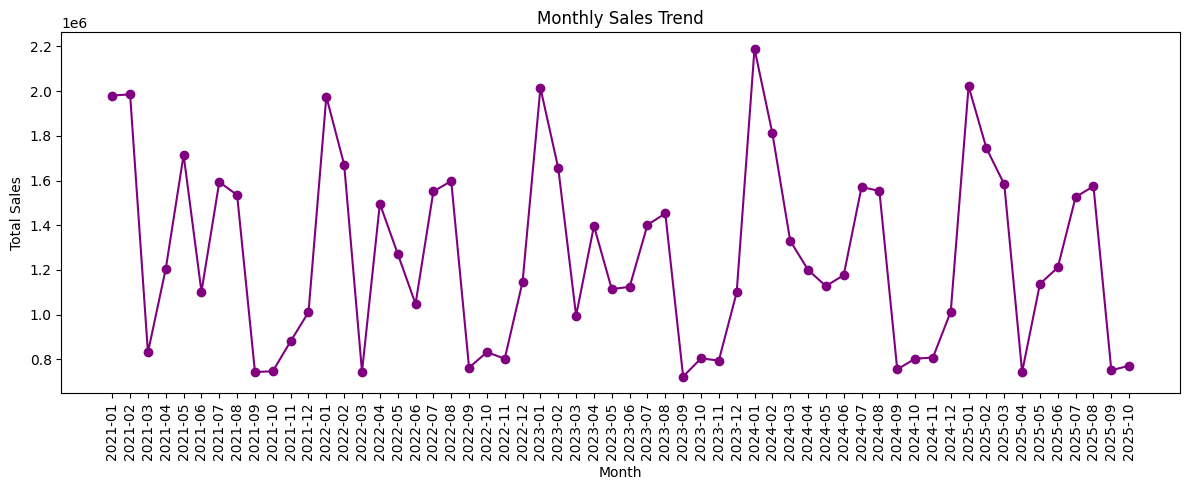

In [108]:
monthly_sales = df.groupby(df['date'].dt.to_period('M'))['total_value'].sum()
monthly_sales.index = monthly_sales.index.astype(str)

### Visualization - Line Chart
plt.figure(figsize=(12,5))
plt.plot(monthly_sales.index,monthly_sales.values,marker='o',color='purple')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

##### 2.Which categories generate highest sales and profit ?

In [109]:
df['profit'] = df['total_value'] -(df['quantity']*df['cost_price'])
category_perf = df.groupby('category').agg(total_sales=('total_value','sum'),
                           total_profit=('profit','sum')).sort_values('total_sales',ascending=False)
category_perf


,total_sales,total_profit
category,,
Electronics,40790950.89,11848265.14
Household,8190735.92,2360418.07
Personal Care,8181799.29,2115959.34
Grocery,5564702.41,1661022.56
Snacks,4321275.25,1299444.11
Dairy,4238161.64,1237884.73
Beverages,1922157.59,574416.61


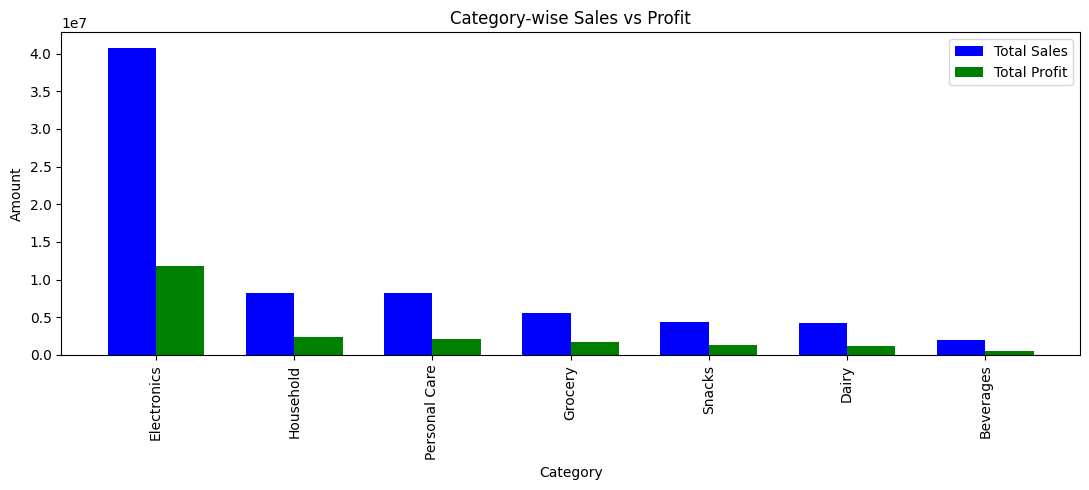

In [110]:
#Visualization= bar chart
category_perf = df.groupby('category').agg(total_sales=('total_value','sum'),
                           total_profit=('profit','sum')).sort_values('total_sales',ascending=False)
category_perf
x=np.arange(len(category_perf)) #[0,1,2,3,4,5,6,7]
width =0.35

plt.figure(figsize=(11,5))
plt.bar(x-width/2,category_perf['total_sales'],width=width,label='Total Sales',color='blue')
plt.bar(x+width/2,category_perf['total_profit'],width=width,label='Total Profit',color='green')
plt.xticks(x,category_perf.index,rotation=90)
plt.xlabel('Category')
plt.ylabel('Amount')
plt.title('Category-wise Sales vs Profit')
plt.legend()
plt.tight_layout()
plt.show()

##### 3.Which Products are most Profitable?

In [111]:
product_perf = df.groupby('subcategory').agg(total_sales=('total_value','sum'),
                           total_profit=('profit','sum'))
product_perf = product_perf.sort_values('total_profit',ascending=False)
top10_profitable = product_perf.head(10)
top10_profitable

,total_sales,total_profit
subcategory,,
Batteries,12530863.56,3961439.04
Cables,11490862.59,3393750.71
Chargers,9227916.96,2311019.26
Mobile Accessories,7541307.78,2182056.13
Cleaning Supplies,3138214.56,898445.37
Paper Products,2745043.37,743314.52
Toothpaste,2403497.14,655592.68
Skincare,2424275.35,551642.10
Canned Goods,1375868.80,449469.99


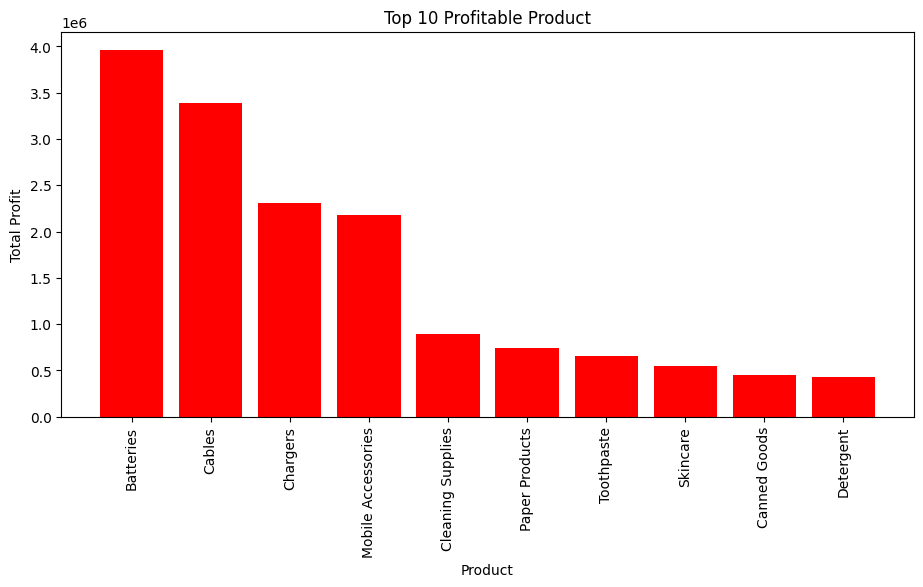

In [112]:
plt.figure(figsize=(11,5))
plt.bar(top10_profitable.index,top10_profitable['total_profit'],color='red')
plt.xlabel('Product')
plt.ylabel('Total Profit')
plt.title('Top 10 Profitable Product')
plt.xticks(rotation=90)
plt.show()

##### 4.Which stores and cities are performing best?

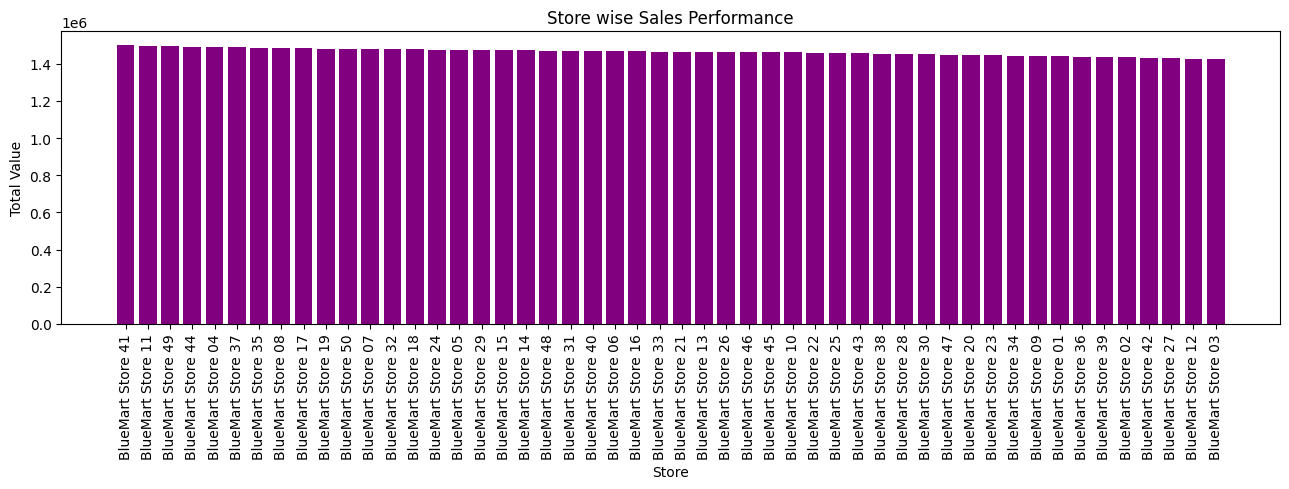

In [113]:
store_perf = df.groupby('store_name')['total_value'].sum().sort_values(ascending=False)
                           
plt.figure(figsize=(13,5))
plt.bar(store_perf.index, store_perf.values,color='purple')
plt.xlabel('Store')
plt.ylabel('Total Value')
plt.title('Store wise Sales Performance')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

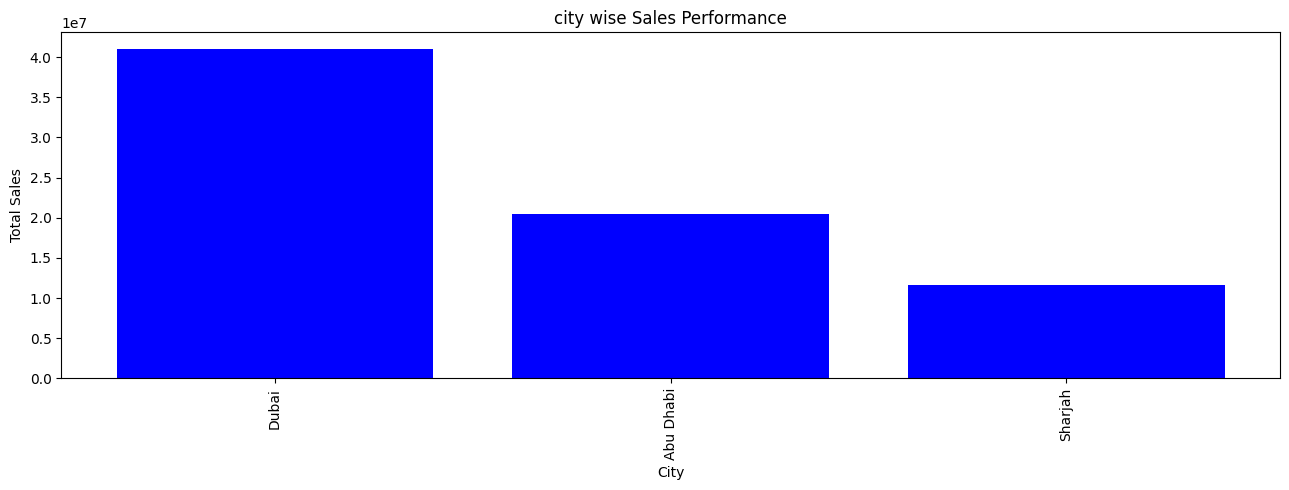

In [114]:
city_perf = df.groupby('city')['total_value'].sum().sort_values(ascending=False)
                           
plt.figure(figsize=(13,5))
plt.bar(city_perf.index, city_perf.values,color='blue')
plt.xlabel('City')
plt.ylabel('Total Sales')
plt.title('city wise Sales Performance')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

##### 5.Which Sales Chennel contributes the most


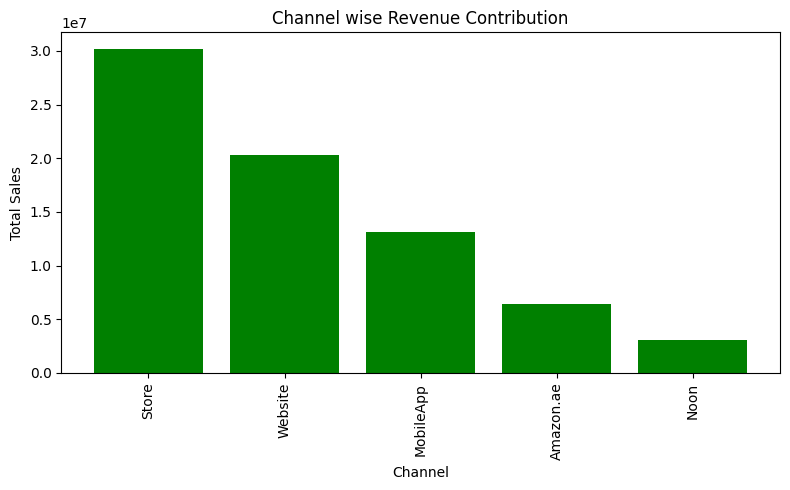

In [115]:
channel_perf = df.groupby('channel')['total_value'].sum().sort_values(ascending=False)
channel_perf                       
plt.figure(figsize=(8,5))
plt.bar(channel_perf.index, channel_perf.values,color='green')
plt.xlabel('Channel')
plt.ylabel('Total Sales')
plt.title('Channel wise Revenue Contribution')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#### Introduction to inventory File

In [116]:
idf = pd.read_csv('bm_inventory.csv')
idf.head()

,store_id,sku_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date
0,9,1101,300,92,46,2025-10-18,2025-10-31
1,9,1021,425,162,81,2025-10-21,2025-10-31
2,9,1200,252,85,42,2025-09-14,2025-10-31
3,9,1041,220,87,43,2025-10-13,2025-10-31
4,9,1092,170,80,40,2025-09-12,2025-10-31


In [117]:
idf.info()

<class 'pandas.DataFrame'>
RangeIndex: 8735 entries, 0 to 8734
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   store_id           8735 non-null   int64
 1   sku_id             8735 non-null   int64
 2   stock_on_hand      8735 non-null   int64
 3   reorder_point      8735 non-null   int64
 4   safety_stock       8735 non-null   int64
 5   last_restock_date  8735 non-null   str  
 6   snapshot_date      8735 non-null   str  
dtypes: int64(5), str(2)
memory usage: 648.4 KB


#### AD-hoc Analysis & Final Insights
###### 1.Which high selling products are at risk of stockout (low inventory)

In [119]:
product_sales = df.groupby('sku_id')['quantity'].sum().reset_index()
product_sales

,sku_id,quantity
0,1001,8545
1,1002,8445
2,1003,8388
3,1004,8301
4,1005,8563
...,...,...
195,1196,8621
196,1197,8358
197,1198,8322
198,1199,8283


In [121]:
risk_df = product_sales.merge(idf,on='sku_id',how='left')
risk_df

,sku_id,quantity,store_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date
0,1001,8545,9,88,40,20,2025-09-26,2025-10-31
1,1001,8545,10,196,68,34,2025-09-06,2025-10-31
2,1001,8545,11,111,52,26,2025-10-29,2025-10-31
3,1001,8545,12,200,71,35,2025-10-17,2025-10-31
4,1001,8545,13,62,25,12,2025-09-05,2025-10-31
...,...,...,...,...,...,...,...,...
8730,1200,8181,46,124,56,28,2025-10-16,2025-10-31
8731,1200,8181,7,229,84,42,2025-10-03,2025-10-31
8732,1200,8181,48,225,80,40,2025-09-04,2025-10-31
8733,1200,8181,49,348,165,82,2025-08-06,2025-10-31


In [ ]:
#High sales + low stock = potential stockout 

In [127]:
high_sales_low_stock = risk_df[(risk_df['quantity']>risk_df['quantity'].median())&
    (risk_df['stock_on_hand']<risk_df['stock_on_hand'].median())]
high_sales_low_stock

,sku_id,quantity,store_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date
0,1001,8545,9,88,40,20,2025-09-26,2025-10-31
2,1001,8545,11,111,52,26,2025-10-29,2025-10-31
4,1001,8545,13,62,25,12,2025-09-05,2025-10-31
6,1001,8545,15,85,31,15,2025-08-14,2025-10-31
7,1001,8545,16,141,43,21,2025-10-13,2025-10-31
...,...,...,...,...,...,...,...,...
8532,1196,8621,1,144,45,22,2025-09-01,2025-10-31
8534,1196,8621,27,144,64,32,2025-09-14,2025-10-31
8544,1196,8621,4,139,61,30,2025-09-09,2025-10-31
8549,1196,8621,40,122,53,26,2025-09-08,2025-10-31


##### 2.Which products are below their reorder point?

In [129]:
low_stock=idf[idf['stock_on_hand']<idf['reorder_point']]
low_stock

,store_id,sku_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date


##### Which products have high sales but low peofit?

In [131]:
product_summary = df.groupby('sku_name').agg(total_sales =('total_value','sum'),
                                             total_profit=('profit','sum'))
product_summary


,total_sales,total_profit
sku_name,,
Beverages_Coffee_1006,96824.87,16523.67
Beverages_Coffee_1141,67713.90,15553.05
Beverages_Juices_1004,192823.87,46892.29
Beverages_Juices_1012,108914.42,43695.73
Beverages_Juices_1020,76798.25,18193.53
...,...,...
Snacks_Nuts_1081,81668.99,18086.61
Snacks_Nuts_1111,103005.40,19404.70
Snacks_Nuts_1130,133901.03,34691.11


In [ ]:
###Sales->Relatively high & Profit -> Relatively low 

In [132]:
high_sales_low_profit = product_summary.loc[(product_summary['total_sales']>product_summary['total_sales'].median())
    & (product_summary['total_profit']<product_summary['total_profit'].median())]
high_sales_low_profit

,total_sales,total_profit
sku_name,,
Dairy_Cream_1015,216990.20,53024.38
Grocery_Canned Goods_1029,221385.97,53295.53
Grocery_Pasta_1196,240533.99,56561.85
Grocery_Rice_1121,252178.55,36236.60
Grocery_Spices_1128,210567.09,53687.09
Household_Cleaning Supplies_1179,225473.13,59049.43
Household_Paper Products_1028,321556.41,58348.01
Personal Care_Soap_1156,279936.17,53765.73
